Librerias

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
archivo = pd.read_csv("ventas_realstate_bsas.csv")

In [ ]:
archivo.head()
archivo.shape # Cantidad de Filas y Columnas
archivo.info() #Tipo de Variables
archivo.describe() #Idea del estadistico global de los campos numericos
archivo.nunique() # unicos x col
archivo.isnull().sum()

Analisis EDA
    

In [18]:
# Campos fecha (str) a formato datetime
archivo['start_date'] = pd.to_datetime(archivo['start_date'])
archivo['end_date'] = pd.to_datetime(archivo['end_date'])
archivo['created_on'] = pd.to_datetime(archivo['created_on'])

# Nuevos campos: dias_publicado y precio_x_m2
archivo['dias_publicado'] = (archivo['end_date'] - archivo['start_date']).dt.days
archivo['precio_usd_m2'] = archivo['price'] / archivo['surface_total']

# Validamos los campos de fechas y creados
archivo[['start_date', 'end_date', 'created_on', 'dias_publicado','precio_usd_m2']].dtypes

# Hay duplicados?
duplicados = archivo.duplicated().sum()

if duplicados > 0:
    archivo = archivo.drop_duplicates()

# Filtro registros que tengan datos completos en las variables clave
df_filtrado = archivo.dropna(subset=['price', 'surface_total', 'surface_covered', 'bathrooms', 'rooms']).copy()

inconsistencias_sup = (df_filtrado['surface_covered'] > df_filtrado['surface_total']).sum()
df_ok = df_filtrado[(df_filtrado['surface_total'] >= df_filtrado['surface_covered'])].copy()

# Analizar Percentiles para las variables con maximos dudoso
#print(df_ok[['rooms', 'bedrooms', 'bathrooms','surface_total', 'surface_covered', 'price', 'precio_usd_m2']].quantile([0.5, 0.75, 0.95, 0.99, 0.999]))


filtro_hab = (
    (df_ok['rooms'] <= 8) & 
    (df_ok['bedrooms'] <= 5) & 
    (df_ok['bathrooms'] <= 5)
)

# Filtro geográfico (manejar lat y log de CABA/GBA habia maximos y minimos)
lat_min, lat_max = -35.2, -34.0
lon_min, lon_max = -59.3, -57.7

filtro_geo = (df_ok['lat'].between(lat_min, lat_max) & df_ok['lon'].between(lon_min, lon_max)
)

filtro_sup = (df_ok['surface_total'].between(15, 800) & df_ok['surface_covered'].between(15, 600)
)

filtro_precio = df_ok['price'].between(20000, 2000000)

filtro_precio_m2 = df_ok['precio_usd_m2'].between(300, 7000)

filtro_tiempo = df_ok['dias_publicado'].between(0, 730)

df_limpio = df_ok[filtro_hab & filtro_geo & filtro_sup & filtro_precio & filtro_precio_m2 & filtro_tiempo].copy()








Filas restantes tras quitar duplicados: 144302


Hipotesis
Hipótesis 1: Paradoja del m2 (Insight).
Hipótesis 2: Segmentación Geográfica.
Hipótesis 3: Relación Lineal de Superficie y Precio.
Hipótesis 4: Liquidez y tipología.
Hipótesis 5: Impacto en la cantidad de baños.

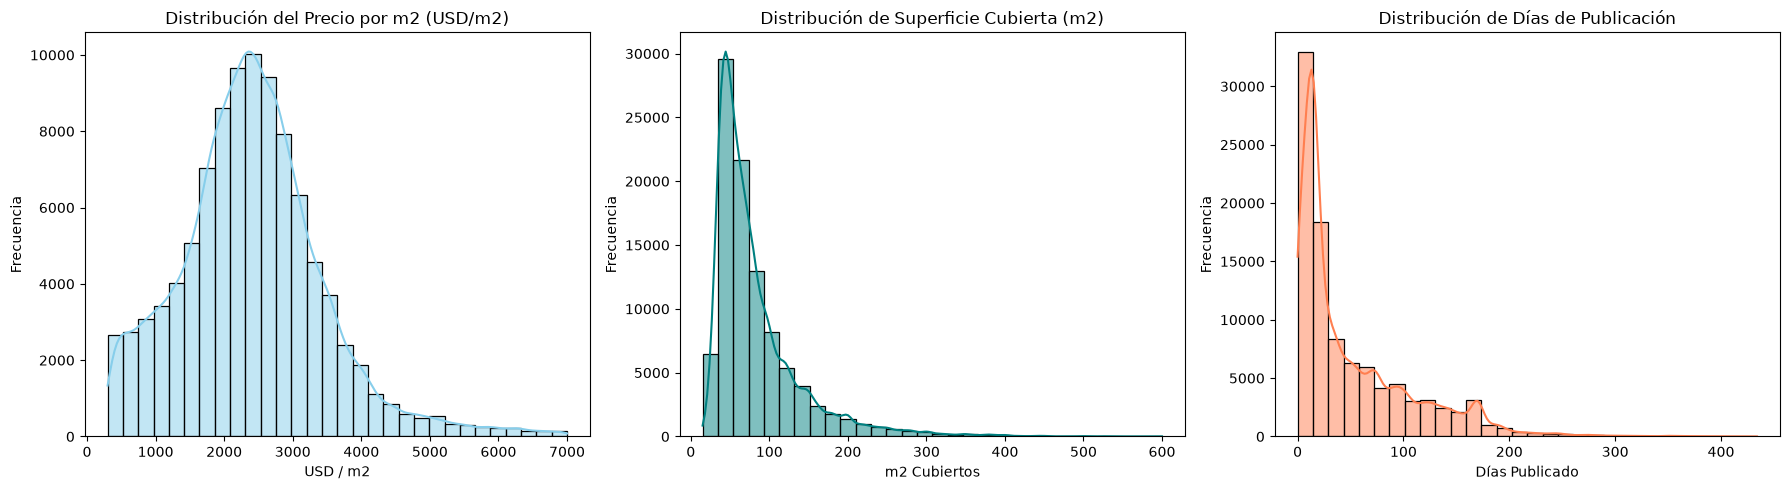

In [14]:
# Histogramas con KDE
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribución del Precio por m2 (USD/m2)
sns.histplot(df_limpio['precio_usd_m2'], kde=True, ax=axes[0], color='skyblue', bins=30)
axes[0].set_title('Distribución del Precio por m2 (USD/m2)')
axes[0].set_xlabel('USD / m2')
axes[0].set_ylabel('Frecuencia')

# Distribución de la Superficie Cubierta
sns.histplot(df_limpio['surface_covered'], kde=True, ax=axes[1], color='teal', bins=30)
axes[1].set_title('Distribución de Superficie Cubierta (m2)')
axes[1].set_xlabel('m2 Cubiertos')
axes[1].set_ylabel('Frecuencia')

# Distribución de Días de Publicación
sns.histplot(df_limpio['dias_publicado'], kde=True, ax=axes[2], color='coral', bins=30)
axes[2].set_title('Distribución de Días de Publicación')
axes[2].set_xlabel('Días Publicado')
axes[2].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

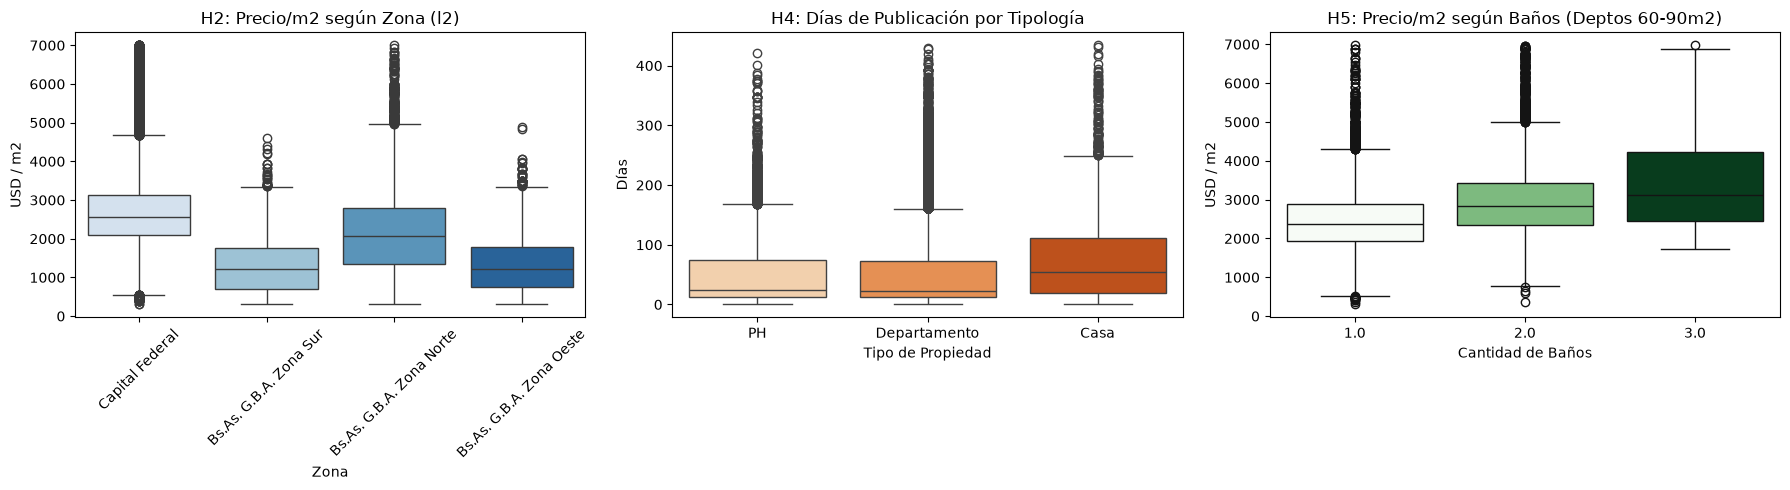

In [9]:
#Boxplots (Analizando H2, H4 y H5)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Boxplot H2: Precio por m2 según Zona
sns.boxplot(data=df_limpio, x='l2', y='precio_usd_m2', hue='l2', legend=False, ax=axes[0], palette='Blues')
axes[0].set_title('H2: Precio/m2 según Zona (l2)')
axes[0].set_xlabel('Zona')
axes[0].set_ylabel('USD / m2')
axes[0].tick_params(axis='x', rotation=45)

# Boxplot H4: Días publicado según Tipo de Propiedad 
tipos_principales = df_limpio['property_type'].value_counts().nlargest(3).index
df_tipos = df_limpio[df_limpio['property_type'].isin(tipos_principales)]

sns.boxplot(data=df_tipos, x='property_type', y='dias_publicado', hue='property_type', legend=False, ax=axes[1], palette='Oranges')
axes[1].set_title('H4: Días de Publicación por Tipología')
axes[1].set_xlabel('Tipo de Propiedad')
axes[1].set_ylabel('Días')

# Boxplot H5: Impacto de Baños en el Precio/m2 entre 60-90m2
deptos_medianos = df_limpio[(df_limpio['property_type'] == 'Departamento') & (df_limpio['surface_total'].between(60, 90)) & (df_limpio['bathrooms'].between(1, 3))]

sns.boxplot(data=deptos_medianos, x='bathrooms', y='precio_usd_m2', hue='bathrooms', legend=False, ax=axes[2], palette='Greens')
axes[2].set_title('H5: Precio/m2 según Baños (Deptos 60-90m2)')
axes[2].set_xlabel('Cantidad de Baños')
axes[2].set_ylabel('USD / m2')

plt.tight_layout()
plt.show()

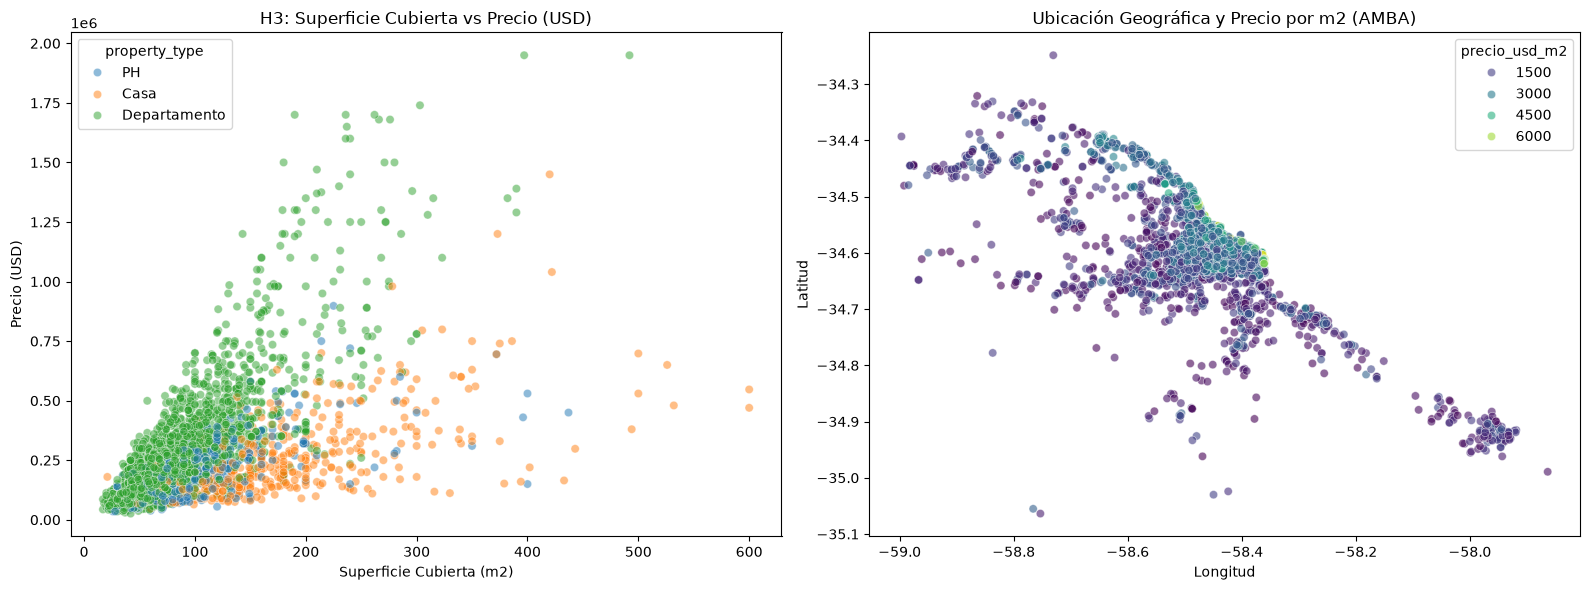

In [10]:
#Scatterplots (Analizando H3 y Ubicación Geográfica)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatterplot H3: Superficie Cubierta vs Precio en USD
sns.scatterplot(data=df_tipos.sample(5000, random_state=42), x='surface_covered', y='price', hue='property_type', alpha=0.5, ax=axes[0])
axes[0].set_title('H3: Superficie Cubierta vs Precio (USD)')
axes[0].set_xlabel('Superficie Cubierta (m2)')
axes[0].set_ylabel('Precio (USD)')

# Scatterplot: Distribución Geográfica (Lat vs Lon) coloreada por Precio/m²
sns.scatterplot(data=df_limpio.sample(5000, random_state=42), x='lon', y='lat', hue='precio_usd_m2', palette='viridis', alpha=0.6, ax=axes[1])
axes[1].set_title('Ubicación Geográfica y Precio por m2 (AMBA)')
axes[1].set_xlabel('Longitud')
axes[1].set_ylabel('Latitud')

plt.tight_layout()
plt.show()

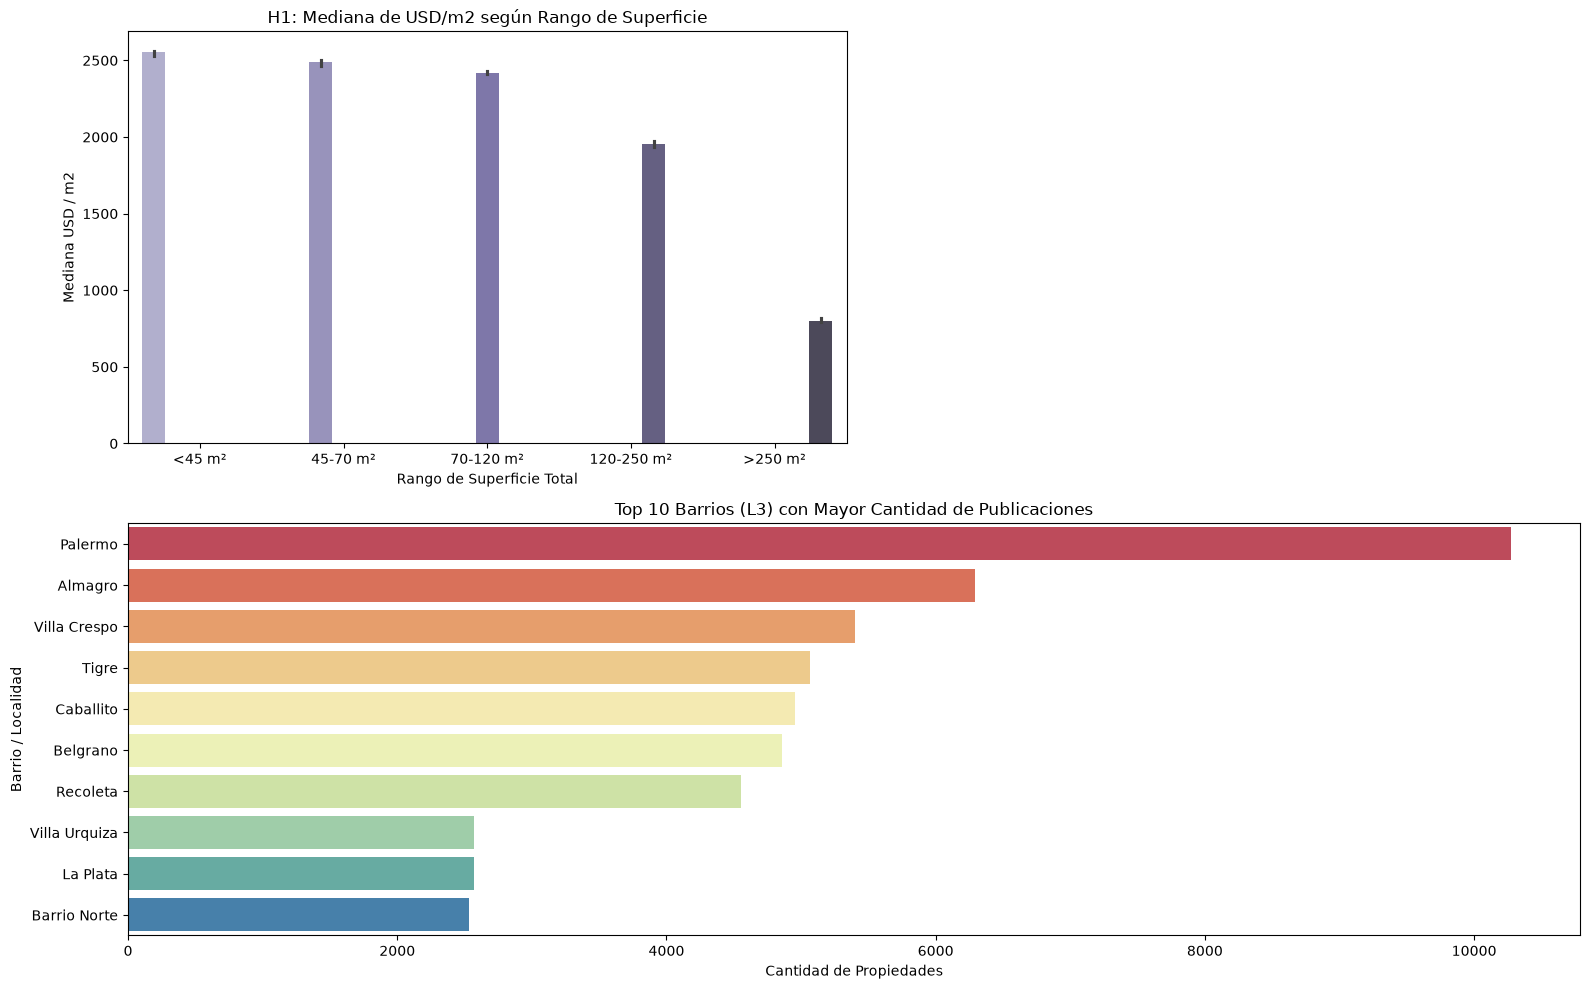

In [12]:
# Adicionales
df_limpio['rango_superficie'] = pd.cut(df_limpio['surface_total'],bins=[15, 45, 70, 120, 250, 800],labels=['<45 m²', '45-70 m²', '70-120 m²', '120-250 m²', '>250 m²'])

fig = plt.figure(figsize=(16, 10))

# La Paradoja del m2 (Insight)
ax1 = plt.subplot(2, 2, 1)
sns.barplot(data=df_limpio, x='rango_superficie', y='precio_usd_m2', estimator='median', hue='rango_superficie', legend=False, palette='Purples_d', ax=ax1)
ax1.set_title('H1: Mediana de USD/m2 según Rango de Superficie')
ax1.set_xlabel('Rango de Superficie Total')
ax1.set_ylabel('Mediana USD / m2')

# Top 10 Barrios (L3) con mayor oferta
ax3 = plt.subplot(2, 1, 2)
top_barrios = df_limpio['l3'].value_counts().head(10)
sns.barplot(x=top_barrios.values, y=top_barrios.index, hue=top_barrios.index, legend=False, palette='Spectral', ax=ax3)
ax3.set_title('Top 10 Barrios (L3) con Mayor Cantidad de Publicaciones')
ax3.set_xlabel('Cantidad de Propiedades')
ax3.set_ylabel('Barrio / Localidad')

plt.tight_layout()
plt.show()

Conclusión sobre el insight (H1)

De los resultados del Análisis Exploratorio de Datos (EDA) extraídos del dataset propiedades inmobiliarias del AMBA, podemos establecer respuestas en relación a la hipótesis que se plantearon:  
H1: La Paradoja del m2 --> Confirmada
Existe una relación inversa entre la superficie total y el valor unitario: a menor tamaño, mayor es el costo por metro cuadrado. Las propiedades pequeñas (de menos de 45 m2) registran el valor por m2 más alto del mercado (superando los 2.400 USD/m2). En cambio, a medida que la superficie aumenta (superando los 120 m2), el costo unitario por m² disminuye progresivamente, estabilizando el precio final del inmueble.

H2 (Geografía): Fuerte brecha territorial, con Capital Federal y Zona Norte concentrando los mayores valores unitarios.
H3 (Precio vs. Superficie): Tendencia lineal ascendente directa, los departamentos cotizan más por m² que las casas a igual superficie.
H4 (Liquidez): Los tiempos de publicación se concentran más en los primeros 30 días, con una mayor rotación en PHs y Departamentos que en Casas.
H5 (Baños): Impacto muy positivo de la cantidad de baños sobre el precio por m² en departamentos estándar (60-90 m²).

